In [1]:
import pandas as pd
df = pd.read_csv("original.csv")
df.shape
df.columns


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')

In [2]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format = 'mixed',dayfirst = True)
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Category"].value_counts()
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format = 'mixed',dayfirst = True)


In [3]:
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Month Name"] = (df["Order Date"]).dt.month_name()
df["Year Month"] = df["Order Date"].dt.to_period("M")

#Kpi's

In [4]:
df.head(10)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Ship Days,Month Name,Year Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,3,November,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,3,November,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,4,June,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,7,October,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,7,October,2016-10
5,6,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,2015,6,5,June,2015-06
6,7,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,2015,6,5,June,2015-06
7,8,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,2015,6,5,June,2015-06
8,9,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by S...,18.5040,2015,6,5,June,2015-06
9,10,CA-2015-115812,2015-06-09,2015-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,2015,6,5,June,2015-06


In [5]:
total_sales = df["Sales"].sum()
print("$",round(total_sales,1))
total_orders = df["Order ID"].nunique()
print(total_orders)
total_customers = df["Customer ID"].nunique()
print(total_customers)
total_products = df["Product ID"].nunique()
print(total_products)
average_order_value = total_sales/total_orders
print("AOV:",round(average_order_value,2))


$ 2261536.8
4922
793
1861
AOV: 459.48


In [6]:
monthly_sales = ( df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum().reset_index())
monthly_sales["Sales"] = monthly_sales["Sales"].round(2)
highest_sales = monthly_sales.sort_values("Sales",ascending = False ).head(10)
monthly_pattern = df.groupby("Month")["Sales"].mean().sort_values(ascending = False).reset_index()

# print(monthly_sales.head(10))
# print()
# print(highest_sales)
monthly_pattern

,Month,Sales
0,3,290.549393
1,1,257.627403
2,10,246.596162
3,11,241.657496
4,12,232.619515
5,8,227.007110
6,9,221.642106
7,5,212.533412
8,6,211.052856
9,7,208.802997


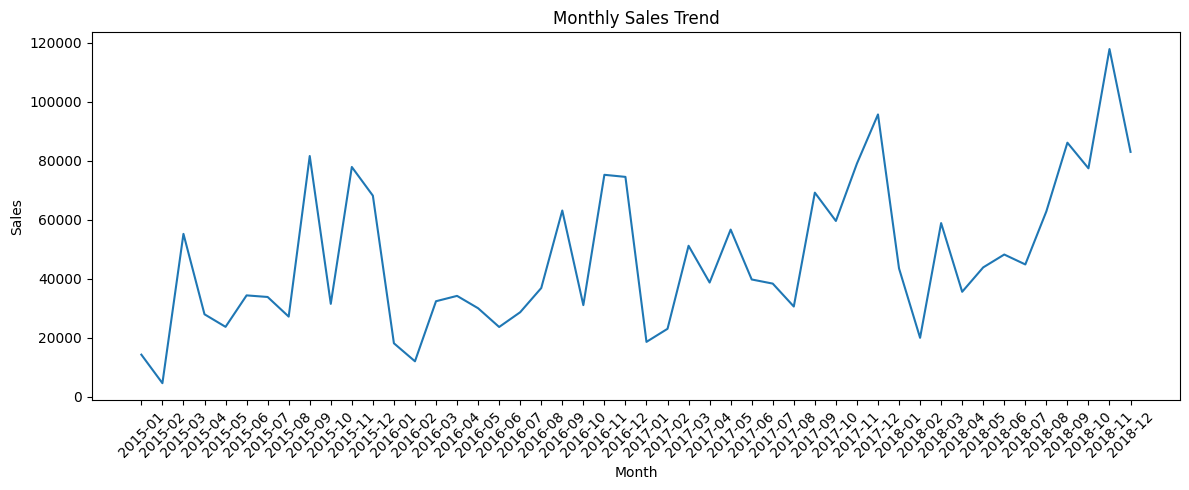

In [7]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Order Date"].astype(str),
    monthly_sales["Sales"]
)

plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

In [8]:
yearly_sales = df.groupby("Year")["Sales"].sum().reset_index().round(2)
yearly_yoy =yearly_sales.copy()
yearly_yoy["YOY Growth"] = yearly_yoy["Sales"].pct_change()*100
yearly_yoy = yearly_yoy.round({
    "Sales" : 2,
    "YOY Growth" : 2})
print(yearly_sales)
yearly_yoy

   Year      Sales
0  2015  479856.21
1  2016  459436.01
2  2017  600192.55
3  2018  722052.02


,Year,Sales,YOY Growth
0,2015,479856.21,NaN
1,2016,459436.01,-4.26
2,2017,600192.55,30.64
3,2018,722052.02,20.30


#Category Analysis

In [54]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending = False).reset_index()
category_sales
category_sales_pct= df.groupby("Category")["Sales"].sum().div(df["Sales"].sum()).mul(100).sort_values(ascending = False).reset_index()
category_sales_pct["Sales"] = category_sales_pct["Sales"].round(2)
category_sales_pct

,Category,Sales
0,Technology,36.59
1,Furniture,32.22
2,Office Supplies,31.19


#Sub Category Analysis

In [10]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending = False).reset_index()
subcategory_sales


,Sub-Category,Sales
0,Phones,327782.4480
1,Chairs,322822.7310
2,Storage,219343.3920
3,Tables,202810.6280
4,Binders,200028.7850
5,Machines,189238.6310
6,Accessories,164186.7000
7,Copiers,146248.0940
8,Bookcases,113813.1987
9,Appliances,104618.4030


In [11]:
cat_subcat = df.groupby(["Category","Sub-Category"])["Sales"].sum().sort_values(ascending = False).reset_index()
cat_subcat

,Category,Sub-Category,Sales
0,Technology,Phones,327782.4480
1,Furniture,Chairs,322822.7310
2,Office Supplies,Storage,219343.3920
3,Furniture,Tables,202810.6280
4,Office Supplies,Binders,200028.7850
5,Technology,Machines,189238.6310
6,Technology,Accessories,164186.7000
7,Technology,Copiers,146248.0940
8,Furniture,Bookcases,113813.1987
9,Office Supplies,Appliances,104618.4030


In [12]:
region_category = pd.pivot_table(
    df,
    values="Sales",
    index="Region",
    columns="Category",
    aggfunc="sum"
)
#without_pvt = df.groupby(["Region", "Category"])["Sales"].sum().sort_values(ascending = False).reset_index()
print(region_category)

Category    Furniture  Office Supplies  Technology
Region                                            
Central   160317.4622       163590.243  168739.208
East      206461.3880       199940.811  263116.527
South     116531.4800       124424.771  148195.208
West      245348.2455       217466.509  247404.930


In [13]:
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending = False).reset_index()
# print(segment_sales)
segment_cross = pd.crosstab(df["Segment"],
                            df["Category"],
                            values = df["Sales"],
                            aggfunc = "sum")
print(segment_cross)
# """This is to tell that crosstab() is mainly used for sount or frequency of rows/records """
# counting = pd.crosstab(df["Segment"],df["Category"])
# print(counting)

Category       Furniture  Office Supplies  Technology
Segment                                              
Consumer     387696.2580       359352.608  401011.665
Corporate    220321.7018       224130.536  244041.837
Home Office  120640.6159       121939.190  182402.371


In [14]:
top_customers = df.groupby(["Customer ID","Customer Name"])["Sales"].sum().sort_values(ascending= False).head(10).reset_index()
print(top_customers)
cust_sales = top_customers["Sales"].sum()
print()
top_contribution = round((cust_sales/total_sales)*(100),2)
print(f" Top customers concentration: {top_contribution}")

top_products = df.groupby(["Product ID","Product Name"])["Sales"].sum().sort_values(ascending = False).head(10).reset_index()
print(top_products)
product_concentration = round((top_products["Sales"].sum()/(df["Sales"].sum()))*100,2)
print(f"Product's concentration: {product_concentration}")

  Customer ID       Customer Name      Sales
0    SM-20320         Sean Miller  25043.050
1    TC-20980        Tamara Chand  19052.218
2    RB-19360        Raymond Buch  15117.339
3    TA-21385        Tom Ashbrook  14595.620
4    AB-10105       Adrian Barton  14473.571
5    KL-16645        Ken Lonsdale  14175.229
6    SC-20095        Sanjit Chand  14142.334
7    HL-15040        Hunter Lopez  12873.298
8    SE-20110        Sanjit Engle  12209.438
9    CC-12370  Christopher Conant  12129.072

 Top customers concentration: 6.8
        Product ID                                       Product Name  \
0  TEC-CO-10004722              Canon imageCLASS 2200 Advanced Copier   
1  OFF-BI-10003527  Fellowes PB500 Electric Punch Plastic Comb Bin...   
2  TEC-MA-10002412  Cisco TelePresence System EX90 Videoconferenci...   
3  FUR-CH-10002024       HON 5400 Series Task Chairs for Big and Tall   
4  OFF-BI-10001359         GBC DocuBind TL300 Electric Binding System   
5  OFF-BI-10000545   GBC Ibimast

In [15]:
region_category_pct = (region_category.div(region_category.sum(axis=1),axis = 0).mul(100))
region_category_pct[["Furniture","Office Supplies","Technology"]] = region_category_pct[["Furniture","Office Supplies","Technology"]].round(2)
print(region_category_pct)

Category  Furniture  Office Supplies  Technology
Region                                          
Central       32.54            33.21       34.25
East          30.84            29.86       39.30
South         29.95            31.97       38.08
West          34.55            30.62       34.83


In [16]:
segment_sales = df.groupby("Segment")["Sales"].sum().sort_values().reset_index()
print(segment_sales)

       Segment         Sales
0  Home Office  4.249822e+05
1    Corporate  6.884941e+05
2     Consumer  1.148061e+06


In [17]:
segment_category = pd.pivot_table(
    df,
    values = "Sales",
    index = "Segment",
    columns = "Category",
    aggfunc = "sum")
segment_category_pct = segment_category.div(segment_category.sum(axis=1),axis=0).mul(100)
segment_category_pct[["Furniture","Office Supplies","Technology"]] = segment_category_pct[["Furniture","Office Supplies","Technology"]].round(2)
print(segment_category)
print("---------------------------------------------------------")
print(segment_category_pct)

Category       Furniture  Office Supplies  Technology
Segment                                              
Consumer     387696.2580       359352.608  401011.665
Corporate    220321.7018       224130.536  244041.837
Home Office  120640.6159       121939.190  182402.371
---------------------------------------------------------
Category     Furniture  Office Supplies  Technology
Segment                                            
Consumer         33.77            31.30       34.93
Corporate        32.00            32.55       35.45
Home Office      28.39            28.69       42.92


In [18]:
"""To get top 3 products in each category."""
product_category = df.groupby(["Category","Product Name"])["Sales"].sum().reset_index()
product_category["Rank"] = (product_category.groupby("Category")["Sales"].rank(method="first",ascending = False))
top_3_by_category = (
    product_category[
        product_category["Rank"] <= 3
    ]
    .sort_values(["Category", "Rank"])
)
print(product_category)
print(top_3_by_category)

        Category                                       Product Name     Sales  \
0      Furniture                   12-1/2 Diameter Round Wall Clock   551.448   
1      Furniture                           24-Hour Round Wall Clock   487.512   
2      Furniture                           36X48 HARDFLOOR CHAIRMAT   369.248   
3      Furniture                   3M Hangers With Command Adhesive   108.040   
4      Furniture                 3M Polarizing Light Filter Sleeves   216.340   
...          ...                                                ...       ...   
1844  Technology  iKross Bluetooth Portable Keyboard + Cell Phon...   477.660   
1845  Technology                         iOttie HLCRIO102 Car Mount   215.892   
1846  Technology                                iOttie XL Car Mount   223.888   
1847  Technology  invisibleSHIELD by ZAGG Smudge-Free Screen Pro...   442.554   
1848  Technology                 netTALK DUO VoIP Telephone Service  1112.788   

       Rank  
0     225.0  

#Geographic analysis

In [19]:
state_sales = df.groupby("State")["Sales"].sum().round(2).sort_values(ascending = False).reset_index()
state_sales["Sales pct"] = state_sales["Sales"].div(df["Sales"].sum()).mul(100).round(2)
top_states = state_sales.head(10).sort_values(by ="Sales",ascending = True)
top_states

,State,Sales,Sales pct
9,Virginia,70636.72,3.12
8,Ohio,75130.35,3.32
7,Michigan,76136.07,3.37
6,Illinois,79236.52,3.50
5,Florida,88436.53,3.91
4,Pennsylvania,116276.65,5.14
3,Washington,135206.85,5.98
2,Texas,168572.53,7.45
1,New York,306361.15,13.55
0,California,446306.46,19.73


In [20]:
state_category = pd.pivot_table(
    df, values="Sales",
    index="State", columns="Category",
    aggfunc="sum")
state_category_total =  pd.pivot_table(
    df, values="Sales",
    index="State", columns="Category",
    aggfunc="sum")
state_category_total["Total Sales"] = state_category_total.sum(axis=1)
print(state_category.head())
print("---------------------------------------------------------------")
print(state_category_total.head())
print("---------------------------------------------------------------")
max_value = state_category.max(axis=1)#give what is the max value
max_category = state_category.idxmax(axis=1) #gives where is the max value belongs
state_best_category = pd.DataFrame({
    "Category" : max_category,
    "Category Value" : max_value})
print(state_best_category.head(10))

Category      Furniture  Office Supplies  Technology
State                                               
Alabama       6332.4800         4209.080    8969.080
Arizona      13525.2910         9996.481   11750.885
Arkansas      3187.5500         4565.330    3925.250
California  152216.5355       139405.748  154684.180
Colorado     13220.2850         7654.984   10966.329
---------------------------------------------------------------
Category      Furniture  Office Supplies  Technology  Total Sales
State                                                            
Alabama       6332.4800         4209.080    8969.080   19510.6400
Arizona      13525.2910         9996.481   11750.885   35272.6570
Arkansas      3187.5500         4565.330    3925.250   11678.1300
California  152216.5355       139405.748  154684.180  446306.4635
Colorado     13220.2850         7654.984   10966.329   31841.5980
---------------------------------------------------------------
                             Category  

In [21]:
city_sales = df.groupby("City")["Sales"].sum().sort_values(ascending = False).reset_index()
city_sales["Sales"] = city_sales["Sales"].round(2)
print(city_sales.head(10))

            City      Sales
0  New York City  252462.55
1    Los Angeles  173420.18
2        Seattle  116106.32
3  San Francisco  109041.12
4   Philadelphia  108841.75
5        Houston   63956.14
6        Chicago   47820.13
7      San Diego   47521.03
8   Jacksonville   44713.18
9        Detroit   42446.94


In [22]:
#print(df["Ship Days"].head(10))
ship_modes= df["Ship Mode"].value_counts().reset_index()
ship_mode_orders = (
    df.groupby("Ship Mode")["Order ID"]
      .nunique()
      .sort_values(ascending=False)
      .reset_index(name="Orders")
)
avg_ship= round(df["Ship Days"].mean(),2)
print(f"-->Average ship days : {avg_ship}")
print("---------------------------------------------------------")
print(f"-->Here it calculates the total records containing ship modes.. \n {ship_modes}")
print("---------------------------------------------------------")
print(f"-->But here we only calculated the unique order records with specific shipping modes.. \n {ship_mode_orders}")
print("---------------------------------------------------------")
ship_mode_orders_pct = (
    df.groupby("Ship Mode")["Order ID"]
      .nunique().div(ship_mode_orders["Orders"].sum()).mul(100).round(2)
      .sort_values(ascending=False)
      .reset_index(name="Orders % PCT")
)
print(ship_mode_orders_pct)
print("---------------------------------------------------------")
ship_by_order = df.groupby("Ship Mode")["Order ID"].nunique().reset_index()
ship_mode_time = df.groupby("Ship Mode")["Ship Days"].mean().sort_values().reset_index(name = "Ship Days")
ship_mode_time["Ship Days"] = ship_mode_time["Ship Days"].round(2)
print(ship_mode_time)
print("---------------------------------------------------------")
total_ship_analysis = pd.merge(
   ship_mode_time,ship_mode_orders_pct,on = "Ship Mode")
print(total_ship_analysis.sort_values(by ="Ship Days",ascending = False))
print("---------------------------------------------------------")
print(df["Ship Days"].describe().round(2))
print("---------------------------------------------------------")
print(df["Ship Mode"].unique())
print("---------------------------------------------------------")


-->Average ship days : 3.96
---------------------------------------------------------
-->Here it calculates the total records containing ship modes.. 
         Ship Mode  count
0  Standard Class   5859
1    Second Class   1902
2     First Class   1501
3        Same Day    538
---------------------------------------------------------
-->But here we only calculated the unique order records with specific shipping modes.. 
         Ship Mode  Orders
0  Standard Class    2945
1    Second Class     944
2     First Class     772
3        Same Day     261
---------------------------------------------------------
        Ship Mode  Orders % PCT
0  Standard Class         59.83
1    Second Class         19.18
2     First Class         15.68
3        Same Day          5.30
---------------------------------------------------------
        Ship Mode  Ship Days
0        Same Day       0.04
1     First Class       2.18
2    Second Class       3.25
3  Standard Class       5.01
-------------------------

In [23]:
region_ship = df.groupby(["Region","Ship Mode"])["Ship Days"].mean().round(2).reset_index()
region_ship
region_ship_pvt = pd.pivot_table(df,
                                 values = "Ship Days",
                                 index = "Region",
                                 columns= "Ship Mode",
                                 aggfunc = "mean").round(2)
region_ship_pvt

Ship Mode,First Class,Same Day,Second Class,Standard Class
Region,,,,
Central,2.31,0.03,3.36,4.98
East,2.21,0.00,3.27,4.97
South,2.12,0.01,3.20,5.01
West,2.10,0.10,3.17,5.07


In [24]:
region_category_rank = (
    region_category
    .stack()
    .reset_index(name="Sales")
    .sort_values("Sales", ascending=False)
)
print(region_category)
region_category_rank

Category    Furniture  Office Supplies  Technology
Region                                            
Central   160317.4622       163590.243  168739.208
East      206461.3880       199940.811  263116.527
South     116531.4800       124424.771  148195.208
West      245348.2455       217466.509  247404.930


,Region,Category,Sales
5,East,Technology,263116.5270
11,West,Technology,247404.9300
9,West,Furniture,245348.2455
10,West,Office Supplies,217466.5090
3,East,Furniture,206461.3880
4,East,Office Supplies,199940.8110
2,Central,Technology,168739.2080
1,Central,Office Supplies,163590.2430
0,Central,Furniture,160317.4622
8,South,Technology,148195.2080


In [25]:
segment_region =pd.pivot_table(df,values="Sales",index = "Region",columns ="Segment",aggfunc="sum").round(2)
print(segment_region)
print("-----------------------------------------------------------")
print(segment_region.idxmax(axis = 1).reset_index(name="Segment"))
print("-----------------------------------------------------------")
segment_region_pct = segment_region.div(segment_region.sum(axis=1),axis=0).mul(100).round(2)
print(segment_region_pct)
print("-----------------------------------------------------------")
pct = segment_region_pct.mean(axis=0)
print(pct)
# segment_category

Segment   Consumer  Corporate  Home Office
Region                                    
Central  250210.52  152031.50     90404.89
East     347906.60  195897.42    125714.70
South    194702.21  120546.87     73902.37
West     355241.19  220018.28    134960.22
-----------------------------------------------------------
    Region   Segment
0  Central  Consumer
1     East  Consumer
2    South  Consumer
3     West  Consumer
-----------------------------------------------------------
Segment  Consumer  Corporate  Home Office
Region                                   
Central     50.79      30.86        18.35
East        51.96      29.26        18.78
South       50.03      30.98        18.99
West        50.02      30.98        19.00
-----------------------------------------------------------
Segment
Consumer       50.70
Corporate      30.52
Home Office    18.78
dtype: float64


In [26]:
print(region_category_pct)
print("-------------------------------------------------------------------")
print(region_category.round(2))
print("-------------------------------------------------------------------")
year_category = pd.pivot_table(df,values="Sales",index="Year",columns="Category",aggfunc="sum").round(2)
year_category["Total Sales"] = year_category.sum(axis=1).round(2)
category_yoy = (year_category.pct_change()*100).round(2)
print(year_category)
print("-------------------------------------------------------------------")
print(category_yoy)
print("-------------------------------------------------------------------")
product_region =pd.pivot_table(df,values="Sales",index="Product Name",columns="Region",aggfunc="sum").round(2)
print(product_region.head())
print("-------------------------------------------------------------------")
product_region.idxmax(axis=0).reset_index(name="Product")
best_product_region = pd.DataFrame({
    "Product" : product_region.idxmax(axis=0),
    "Product Sales": product_region.max(axis=0)})
print(best_product_region)
print("-------------------------------------------------------------------")

Category  Furniture  Office Supplies  Technology
Region                                          
Central       32.54            33.21       34.25
East          30.84            29.86       39.30
South         29.95            31.97       38.08
West          34.55            30.62       34.83
-------------------------------------------------------------------
Category  Furniture  Office Supplies  Technology
Region                                          
Central   160317.46        163590.24   168739.21
East      206461.39        199940.81   263116.53
South     116531.48        124424.77   148195.21
West      245348.25        217466.51   247404.93
-------------------------------------------------------------------
Category  Furniture  Office Supplies  Technology  Total Sales
Year                                                         
2015      156477.88        149512.82   173865.51    479856.21
2016      164053.87        133124.41   162257.73    459436.01
2017      195813.04        1

In [27]:
product_region_sales = (
    product_region
    .reset_index()
    .melt(
        id_vars="Product Name",
        var_name="Region",
        value_name="Sales"
    )
)
product_region_sales["Rank"] = (
    product_region_sales
    .groupby("Region")["Sales"]
    .rank(method="first", ascending=False)
)
top_3_products_region = (
    product_region_sales[
        product_region_sales["Rank"] <= 3
    ]
    .sort_values(["Region", "Rank"])
)

product_region_sales.head(10)
top_3_products_region

,Product Name,Region,Sales,Rank
404,Canon imageCLASS 2200 Advanced Copier,Central,17499.95,1.0
984,Lexmark MX611dhe Monochrome Laser Printer,Central,14279.92,2.0
894,Ibico EPK-21 Electric Binding System,Central,11339.94,3.0
2253,Canon imageCLASS 2200 Advanced Copier,East,30099.91,1.0
1868,"3D Systems Cube Printer, 2nd Generation, Magenta",East,14299.89,2.0
3199,"Riverside Palais Royal Lawyers Bookcase, Royal...",East,11717.03,3.0
4142,Cisco TelePresence System EX90 Videoconferenci...,South,22638.48,1.0
4484,HP Designjet T520 Inkjet Large Format Printer ...,South,11374.94,2.0
4383,GBC DocuBind TL300 Electric Binding System,South,8342.01,3.0
5951,Canon imageCLASS 2200 Advanced Copier,West,13999.96,1.0


In [28]:
year_segment = pd.pivot_table(df,values="Sales",index="Year",columns="Segment",aggfunc="sum").round(2)
year_segment_pct = year_segment.div(year_segment.sum(axis =1),axis=0).mul(100).round(2)
print(year_segment_pct)
print("-----------------------------------------------------")
print(year_segment)
print("-----------------------------------------------------")
year_segment_yoy = (year_segment.pct_change()*100).round(2)
print(year_segment_yoy)

Segment  Consumer  Corporate  Home Office
Year                                     
2015        54.80      26.63        18.57
2016        57.76      26.05        16.19
2017        48.51      34.15        17.34
2018        45.51      32.69        21.80
-----------------------------------------------------
Segment   Consumer  Corporate  Home Office
Year                                      
2015     262956.80  127797.50     89101.91
2016     265356.29  119675.60     74404.11
2017     291142.97  204977.32    104072.27
2018     328604.47  236043.66    157403.88
-----------------------------------------------------
Segment  Consumer  Corporate  Home Office
Year                                     
2015          NaN        NaN          NaN
2016         0.91      -6.36       -16.50
2017         9.72      71.28        39.87
2018        12.87      15.16        51.24


In [29]:
print(segment_category)
print("-------------------------------------------------------")
segment_category_pct

Category       Furniture  Office Supplies  Technology
Segment                                              
Consumer     387696.2580       359352.608  401011.665
Corporate    220321.7018       224130.536  244041.837
Home Office  120640.6159       121939.190  182402.371
-------------------------------------------------------


Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,33.77,31.30,34.93
Corporate,32.00,32.55,35.45
Home Office,28.39,28.69,42.92


In [30]:
state_rank = df.groupby("State")["Sales"].sum().sort_values(ascending = False).reset_index().round(2)
state_rank["Rank"] = state_rank["Sales"].rank(method ="dense",ascending = False)
state_rank

,State,Sales,Rank
0,California,446306.46,1.0
1,New York,306361.15,2.0
2,Texas,168572.53,3.0
3,Washington,135206.85,4.0
4,Pennsylvania,116276.65,5.0
5,Florida,88436.53,6.0
6,Illinois,79236.52,7.0
7,Michigan,76136.07,8.0
8,Ohio,75130.35,9.0
9,Virginia,70636.72,10.0


In [31]:
total_sales = df["Sales"].sum()

total_orders = df["Order ID"].nunique()

total_customers = df["Customer ID"].nunique()

avg_order_value = total_sales / total_orders

sales_per_customer = total_sales / total_customers
orders_per_customer = total_orders / total_customers

print("Total Sales:", total_sales)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", avg_order_value)
print("Sales Per Customer:", sales_per_customer)
print("Orders Per Customer:", round(orders_per_customer, 2))
print("---------------------------------------------------------------------")
KPI_S = pd.DataFrame({ "Kpi's": ["Total Sales","Total Orders","Total Customers","Average Order Value","Sales Per Customer","Orders Per Customer"],
                       "Values": [total_sales,total_orders,total_customers,avg_order_value,sales_per_customer,orders_per_customer]}).round(2)
KPI_S

Total Sales: 2261536.7827
Total Orders: 4922
Total Customers: 793
Average Order Value: 459.4751691791954
Sales Per Customer: 2851.8748836065574
Orders Per Customer: 6.21
---------------------------------------------------------------------


,Kpi's,Values
0,Total Sales,2261536.78
1,Total Orders,4922.00
2,Total Customers,793.00
3,Average Order Value,459.48
4,Sales Per Customer,2851.87
5,Orders Per Customer,6.21


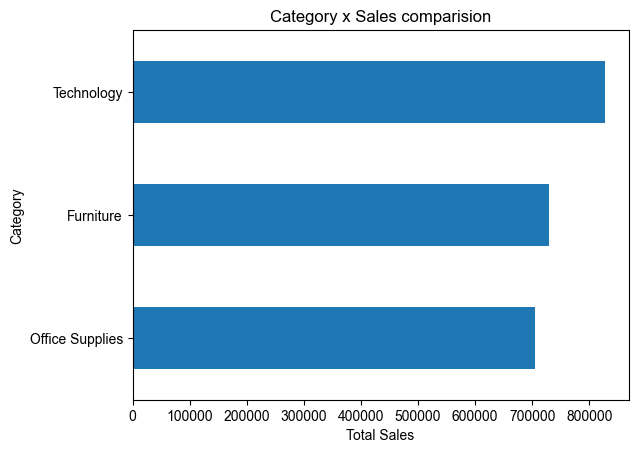

In [32]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=True).round(2)

category_sales.plot(
    kind="barh"
)
plt.style.use("seaborn-v0_8")
plt.title("Category x Sales comparision")
plt.ylabel("Category")
plt.xlabel("Total Sales")
plt.show()

<Figure size 1000x600 with 0 Axes>

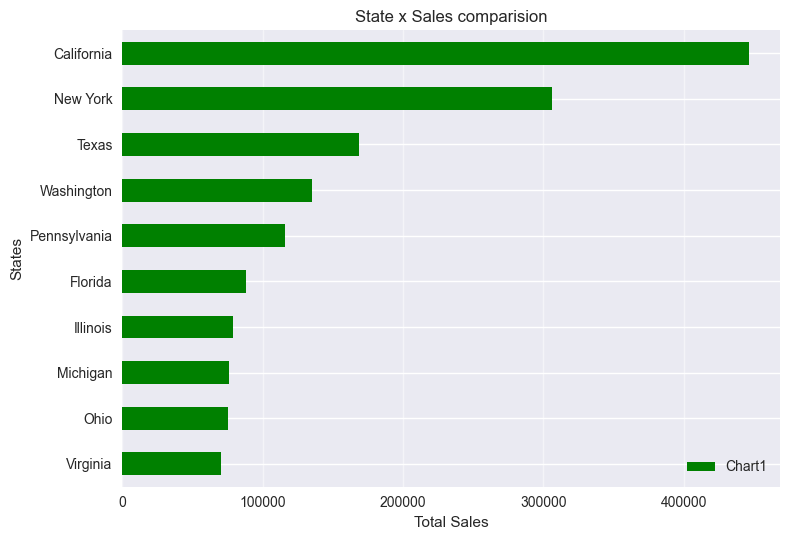

In [33]:
plt.figure(figsize=(10, 6))
top_states.plot(
    kind="barh",x="State",y="Sales",color="g",label="Chart1"
)

plt.title("State x Sales comparision")
plt.ylabel("States")
plt.xlabel("Total Sales")
plt.legend()
plt.tight_layout()
plt.grid(axis="x",alpha=0.5)
plt.show()

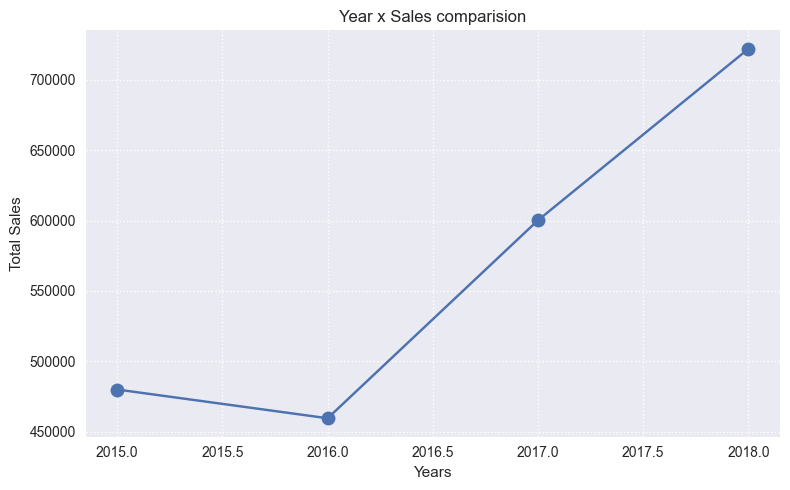

In [46]:
plt.figure(figsize=(8,5))
plt.plot(yearly_sales["Year"],yearly_sales["Sales"],marker="o",markersize=10,linestyle="-")
plt.title("Year x Sales comparision")
plt.xlabel("Years")
plt.ylabel("Total Sales")
plt.grid(True,linestyle=":")
plt.tight_layout()
plt.show()

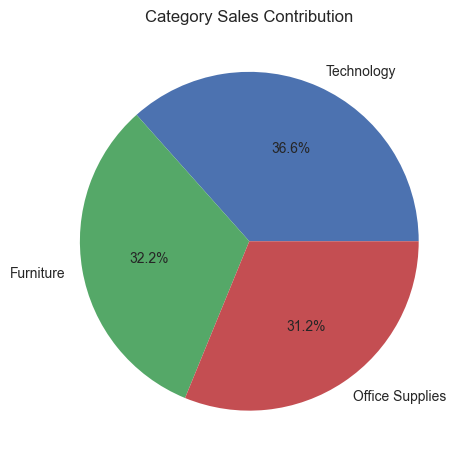

,Category,Sales
0,Technology,36.59
1,Furniture,32.22
2,Office Supplies,31.19


In [79]:
plt.pie(category_sales_pct["Sales"],labels=category_sales_pct["Category"],autopct="%1.1f%%")
plt.title("Category Sales Contribution")
plt.show()
category_sales_pct

Category  Furniture  Office Supplies  Technology
Region                                          
Central   160317.46        163590.24   168739.21
East      206461.39        199940.81   263116.53
South     116531.48        124424.77   148195.21
West      245348.25        217466.51   247404.93


<Axes: xlabel='Region'>

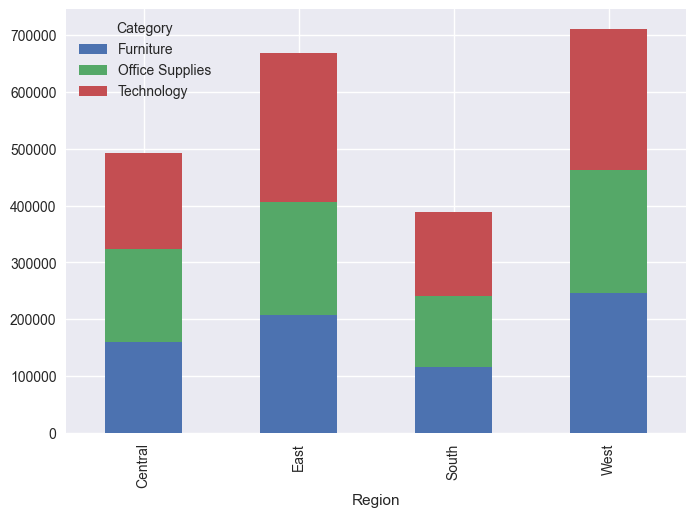

In [70]:
region_category = region_category.round(2)
print(region_category)
region_category.plot(kind="bar",stacked=True)

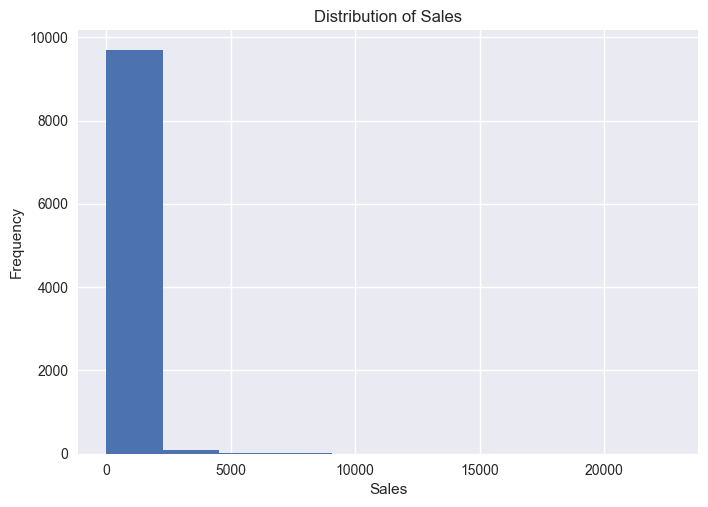

In [81]:
plt.hist(df["Sales"],bins=10)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Distribution of Sales")
plt.show()

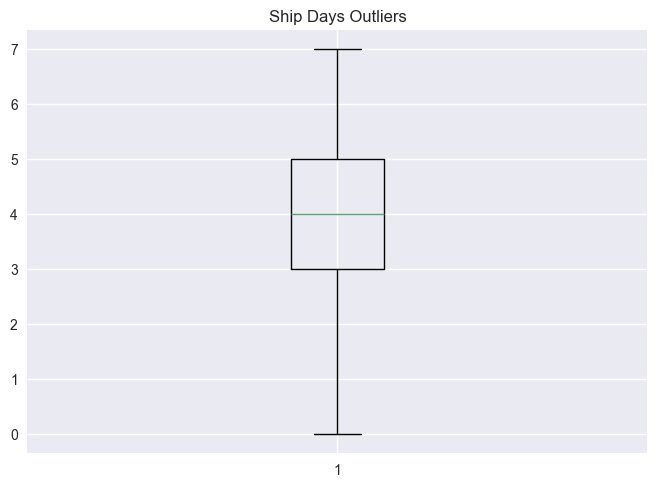

In [86]:
plt.boxplot(df["Ship Days"])
plt.title("Ship Days Outliers")
plt.show()

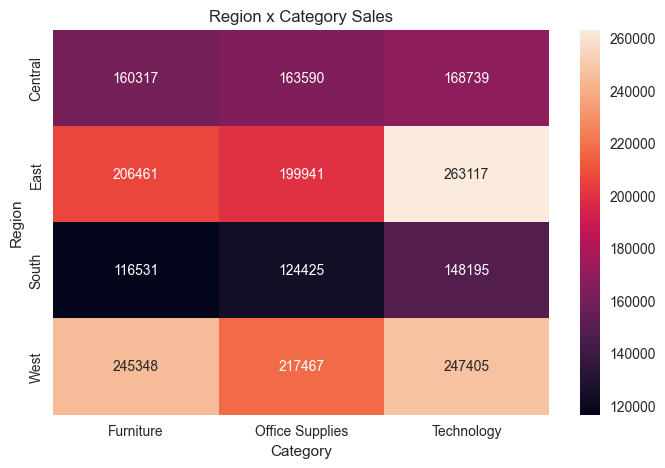

Category,Furniture,Office Supplies,Technology
Region,,,
Central,160317.46,163590.24,168739.21
East,206461.39,199940.81,263116.53
South,116531.48,124424.77,148195.21
West,245348.25,217466.51,247404.93


In [97]:
import seaborn as sns
plt.figure(figsize=(8,5))
sns.heatmap( region_category,fmt=".0f",annot=True)
plt.title("Region x Category Sales")
plt.show()
region_category